In [1]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Gestion du déséquilibre
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Modélisation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Autres
import joblib
import json

# Paramètres d'affichage
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Toutes les bibliothèques ont été importées avec succès.")

Toutes les bibliothèques ont été importées avec succès.


In [ ]:
# Chargement du dataset nettoyé
from pathlib import Path
import pandas as pd

CHEMIN_DATASET = Path("data") / "train_clean.csv"

if not CHEMIN_DATASET.exists():
    raise FileNotFoundError(
        f"Dataset introuvable : {CHEMIN_DATASET.resolve()}\n"
        "Vérifie que train_clean.csv est bien placé dans le dossier data/ "
        "à la racine du projet."
    )

df = pd.read_csv(CHEMIN_DATASET)

# Affichage des dimensions
print("Dimensions du dataset :", df.shape)

# Affichage des premières lignes
display(df.head())

In [3]:
# Informations générales
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_unique               23524 non-null  object
 1   country                 23524 non-null  object
 2   year                    23524 non-null  int64 
 3   location_type           23524 non-null  object
 4   cellphone_access        23524 non-null  object
 5   household_size          23524 non-null  int64 
 6   age_of_respondent       23524 non-null  int64 
 7   age_group               23524 non-null  object
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
 13  flag_age_role           23524 non-null  int64 
 14  flag_age_outlier        23524 non-null  int64 
 15  fl

In [4]:
# Vérification des valeurs manquantes
print("Valeurs manquantes :")
display(df.isnull().sum())

# Vérification des doublons
print("Nombre de doublons :", df.duplicated().sum())

# Vérification des modalités de la cible
print("\nRépartition de la cible :")
display(df["bank_account"].value_counts())

# Vérification des proportions
display(
    df["bank_account"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Valeurs manquantes :


id_unique                 0
country                   0
year                      0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
age_group                 0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
flag_age_role             0
flag_age_outlier          0
flag_hh_outlier           0
bank_account              0
dtype: int64

Nombre de doublons : 0

Répartition de la cible :


bank_account
0    20212
1     3312
Name: count, dtype: int64

bank_account
0    85.92
1    14.08
Name: proportion, dtype: float64

### Définition de X et y

In [5]:
# Séparation des variables explicatives et de la cible

X = df.drop(
    columns=["bank_account", "id_unique", "year"]
)

y = df["bank_account"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())

Dimensions de X : (23524, 14)
Dimensions de y : (23524,)

Variables explicatives :
['country', 'location_type', 'cellphone_access', 'household_size', 'age_of_respondent', 'age_group', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type', 'flag_age_role', 'flag_age_outlier', 'flag_hh_outlier']


### Identification des variables numériques et catégorielles

In [6]:
# Identification des variables numériques
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identification des variables catégorielles
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables numériques :")
print(numerical_features)

print("\nVariables catégorielles :")
print(categorical_features)

Variables numériques :
['household_size', 'age_of_respondent', 'flag_age_role', 'flag_age_outlier', 'flag_hh_outlier']

Variables catégorielles :
['country', 'location_type', 'cellphone_access', 'age_group', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']


### Découpage Train/Test

In [7]:
# Création de la variable de stratification
stratification = (
    df["country"].astype(str)
    + "_"
    + y.astype(str)
)

# Découpage des données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratification
)

print("Dimensions des ensembles :")
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

Dimensions des ensembles :
X_train : (18819, 14)
X_test : (4705, 14)
y_train : (18819,)
y_test : (4705,)


### Vérification du découpage

In [8]:
print("Répartition dans les données initiales :")
print(y.value_counts(normalize=True) * 100)

print("\nRépartition dans Train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nRépartition dans Test :")
print(y_test.value_counts(normalize=True) * 100)

Répartition dans les données initiales :
bank_account
0    85.920762
1    14.079238
Name: proportion, dtype: float64

Répartition dans Train :
bank_account
0    85.918487
1    14.081513
Name: proportion, dtype: float64

Répartition dans Test :
bank_account
0    85.929862
1    14.070138
Name: proportion, dtype: float64


#### Création du préprocesseur

In [9]:
# Transformation des variables catégorielles
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Transformation des variables numériques
numerical_transformer = StandardScaler()

# Combinaison des transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Préprocesseur créé avec succès.")

Préprocesseur créé avec succès.


### Vérification du prétraitement

In [10]:
# Ajustement sur les données d'entraînement uniquement
X_train_transformed = preprocessor.fit_transform(X_train)

# Transformation des données de test
X_test_transformed = preprocessor.transform(X_test)

print("Dimensions après transformation :")
print("Train :", X_train_transformed.shape)
print("Test :", X_test_transformed.shape)

Dimensions après transformation :
Train : (18819, 48)
Test : (4705, 48)


### Comparaison des proportions

In [11]:
print("Avant équilibrage :")
print(y_train.value_counts())

print("\nProportions :")
print(y_train.value_counts(normalize=True) * 100)

Avant équilibrage :
bank_account
0    16169
1     2650
Name: count, dtype: int64

Proportions :
bank_account
0    85.918487
1    14.081513
Name: proportion, dtype: float64


### Importer les outils de validation

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline

### Créer le prétraitement

In [13]:
def creer_preprocesseur():
    transformateur_numerique = StandardScaler()

    transformateur_categoriel = OneHotEncoder(
        handle_unknown="ignore"
    )

    preprocesseur = ColumnTransformer(
        transformers=[
            ("num", transformateur_numerique, numerical_features),
            ("cat", transformateur_categoriel, categorical_features)
        ]
    )

    return preprocesseur

### Définir les modèles et les stratégies

In [14]:
# Calcul du rapport entre les classes
rapport_classes = (
    y_train.value_counts()[0] / y_train.value_counts()[1]
)

# Définition des modèles
modeles = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Logistic Regression - Balanced": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest - Balanced": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ),

    "XGBoost - Weighted": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=rapport_classes,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

# Définition des stratégies de rééquilibrage
strategies = {
    "Sans équilibrage": None,
    "OverSampling": RandomOverSampler(random_state=42),
    "UnderSampling": RandomUnderSampler(random_state=42)
}

### Construire les pipelines

In [15]:
pipelines = {}

for nom_modele, modele in modeles.items():

    # Les stratégies de rééquilibrage sont testées
    # avec la régression logistique classique.
    if nom_modele == "Logistic Regression":

        for nom_strategie, strategie in strategies.items():

            nom_pipeline = f"{nom_modele} - {nom_strategie}"

            etapes = [
                ("pretraitement", creer_preprocesseur())
            ]

            if strategie is not None:
                etapes.append(("equilibrage", strategie))

            etapes.append(("modele", modele))

            pipelines[nom_pipeline] = ImbPipeline(etapes)

    else:
        pipelines[nom_modele] = ImbPipeline([
            ("pretraitement", creer_preprocesseur()),
            ("modele", modele)
        ])

print("Nombre de pipelines à comparer :", len(pipelines))

Nombre de pipelines à comparer : 6


### Effectuer la validation croisée

In [16]:
validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metriques = {
    "precision": "precision",
    "rappel": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision"
}

resultats = []

for nom, pipeline in pipelines.items():

    print(f"Évaluation de : {nom}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=validation,
        scoring=metriques,
        n_jobs=-1
    )

    resultats.append({
        "Modèle": nom,
        "Précision": scores["test_precision"].mean(),
        "Rappel": scores["test_rappel"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Average Precision": scores["test_average_precision"].mean()
    })

tableau_resultats = pd.DataFrame(resultats)

tableau_resultats = tableau_resultats.sort_values(
    by="Average Precision",
    ascending=False
)

display(tableau_resultats.round(4))

Évaluation de : Logistic Regression - Sans équilibrage
Évaluation de : Logistic Regression - OverSampling
Évaluation de : Logistic Regression - UnderSampling
Évaluation de : Logistic Regression - Balanced
Évaluation de : Random Forest - Balanced
Évaluation de : XGBoost - Weighted


,Modèle,Précision,Rappel,F1-score,Balanced Accuracy,Average Precision
5,XGBoost - Weighted,0.3774,0.7600,0.5042,0.7770,0.5863
0,Logistic Regression - Sans équilibrage,0.6758,0.3396,0.4519,0.6564,0.5654
3,Logistic Regression - Balanced,0.3781,0.7404,0.5005,0.7702,0.5632
1,Logistic Regression - OverSampling,0.3750,0.7434,0.4985,0.7701,0.5628
2,Logistic Regression - UnderSampling,0.3695,0.7442,0.4936,0.7677,0.5605
4,Random Forest - Balanced,0.4174,0.5483,0.4739,0.7114,0.4416


### Entraîner le modèle retenu

In [17]:
modele_final = pipelines["XGBoost - Weighted"]

modele_final.fit(X_train, y_train)

print("Entraînement du modèle terminé.")

Entraînement du modèle terminé.


### Effectuer les prédictions

In [18]:
y_pred = modele_final.predict(X_test)

y_proba = modele_final.predict_proba(X_test)[:, 1]

print("Prédictions effectuées avec succès.")

Prédictions effectuées avec succès.


### Évaluer les performances

In [19]:
print("Rapport de classification :")
print(classification_report(y_test, y_pred))

print("Balanced Accuracy :",
      balanced_accuracy_score(y_test, y_pred))

print("Average Precision :",
      average_precision_score(y_test, y_proba))

print("ROC-AUC :",
      roc_auc_score(y_test, y_proba))

Rapport de classification :
              precision    recall  f1-score   support

           0       0.95      0.79      0.87      4043
           1       0.38      0.77      0.51       662

    accuracy                           0.79      4705
   macro avg       0.67      0.78      0.69      4705
weighted avg       0.87      0.79      0.81      4705

Balanced Accuracy : 0.7801868209796052
Average Precision : 0.5793911689863309
ROC-AUC : 0.8659728911183628


### Interprétation
 Le modèle XGBoost pondéré a été retenu à l'issue de la comparaison des différentes configurations. Sur les données de test, il obtient une accuracy de 79 %, une Balanced Accuracy de 78,02 % et un ROC-AUC de 86,60 %. Il identifie correctement 79 % des personnes ne possédant pas de compte bancaire et 77 % de celles qui en possèdent un. Cependant, sa précision pour la classe 1 reste relativement faible (38 %), ce qui traduit un nombre important de fausses prédictions positives. Globalement, le modèle présente une capacité intéressante à distinguer les deux catégories, mais ses prédictions doivent encore être améliorées et interprétées avec prudence.

### Afficher la matrice de confusion

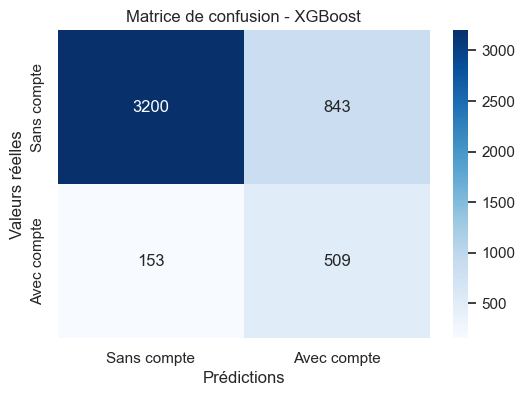

In [20]:
matrice = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    matrice,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sans compte", "Avec compte"],
    yticklabels=["Sans compte", "Avec compte"]
)

plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.title("Matrice de confusion - XGBoost")
plt.show()

### Interprétation
La matrice de confusion montre que le modèle XGBoost a correctement classé 3 200 personnes ne possédant pas de compte bancaire et 509 personnes en possédant un. Cependant, il a commis 843 erreurs de classification parmi les personnes sans compte bancaire et 153 parmi celles possédant un compte. Ces résultats confirment que le modèle identifie relativement bien les deux catégories, mais présente un nombre important de faux positifs. Il serait donc intéressant d'améliorer ses performances afin de réduire ces erreurs.

### Créer le dossier et sauvegarder le modèle

In [ ]:
# Sauvegarde du pipeline et de ses colonnes d'entrée
from pathlib import Path
import json
import joblib

DOSSIER_MODELES = Path("models")
DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)

chemin_modele = DOSSIER_MODELES / "modele_inclusion_financiere.joblib"
chemin_colonnes = DOSSIER_MODELES / "colonnes_entree.json"

joblib.dump(modele_final, chemin_modele)

colonnes_entree = X.columns.tolist()
with chemin_colonnes.open("w", encoding="utf-8") as fichier:
    json.dump(colonnes_entree, fichier, ensure_ascii=False, indent=4)

print("Pipeline sauvegardé :", chemin_modele)
print("Colonnes sauvegardées :", chemin_colonnes)
print("Nombre de variables d'entrée :", len(colonnes_entree))

### Les colonnes d'entrée du modèle

In [ ]:
# La liste des colonnes est désormais sauvegardée avec le pipeline
# dans le dossier models/ par la cellule précédente.

### Vérifier les fichiers

In [ ]:
from pathlib import Path

DOSSIER_MODELES = Path("models")
fichiers_attendus = [
    DOSSIER_MODELES / "modele_inclusion_financiere.joblib",
    DOSSIER_MODELES / "colonnes_entree.json"
]

for chemin in fichiers_attendus:
    print(f"{chemin} :", "présent" if chemin.exists() else "absent")

In [ ]:
# Sauvegarde centralisée : voir la cellule précédente.
# Cette cellule est conservée pour préserver la structure du notebook.

---
## Analyses complémentaires : évaluation approfondie et vérification des hypothèses

Cette dernière partie réutilise le jeu de test (`X_test`, `y_test`) et le modèle final (`modele_final`) définis plus haut. Elle produit les figures 8 à 10 et les résultats des tableaux 10 et 11 du rapport : courbes ROC et précision-rappel, choix du seuil de décision, importance des variables et vérification des hypothèses H1 à H6 issues de l'EDA.

### Matrice de confusion, courbes ROC et précision-rappel

Average Precision : 0.5794 | ROC-AUC : 0.8660
Matrice de confusion : VN=3200, FP=843, FN=153, VP=509


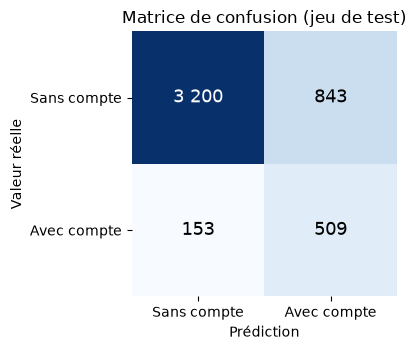

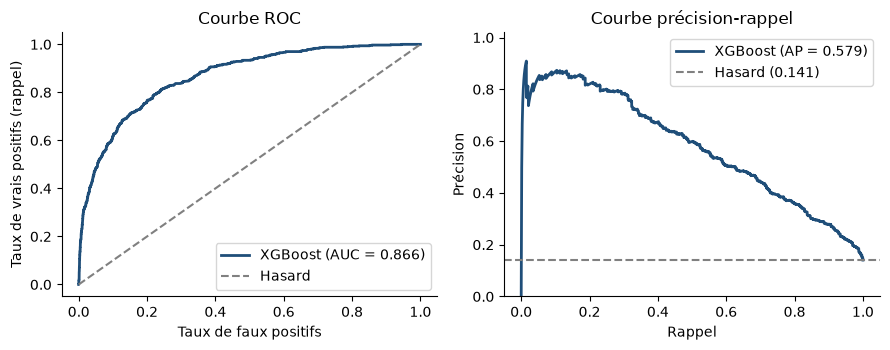

In [25]:
import os
from sklearn.metrics import roc_curve, precision_recall_curve

os.makedirs("figures", exist_ok=True)
C1, C2 = "#1f4e79", "#d98a1a"

AP0 = average_precision_score(y_test, y_proba)
AUC0 = roc_auc_score(y_test, y_proba)
print(f"Average Precision : {AP0:.4f} | ROC-AUC : {AUC0:.4f}")

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Matrice de confusion : VN={tn}, FP={fp}, FN={fn}, VP={tp}")

with plt.style.context("default"):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

    # Figure 8 : matrice de confusion
    cm = np.array([[tn, fp], [fn, tp]])
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", " "), ha="center", va="center",
                    fontsize=13, color="white" if cm[i, j] > 1800 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Sans compte", "Avec compte"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Sans compte", "Avec compte"])
    ax.set_xlabel("Prédiction"); ax.set_ylabel("Valeur réelle")
    ax.set_title("Matrice de confusion (jeu de test)")
    ax.spines[:].set_visible(False)
    plt.tight_layout(); plt.savefig("figures/f8_matrice_confusion.png", dpi=110); plt.show()

    # Figure 9 : courbes ROC et précision-rappel
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    prec, rapp, _ = precision_recall_curve(y_test, y_proba)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
    ax[0].plot(fpr, tpr, color=C1, lw=2, label=f"XGBoost (AUC = {AUC0:.3f})")
    ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Hasard")
    ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de vrais positifs (rappel)")
    ax[0].set_title("Courbe ROC"); ax[0].legend(loc="lower right")
    ax[1].plot(rapp[:-1], prec[:-1], color=C1, lw=2, label=f"XGBoost (AP = {AP0:.3f})")
    ax[1].axhline(y_test.mean(), ls="--", color="grey", label=f"Hasard ({y_test.mean():.3f})")
    ax[1].set_xlabel("Rappel"); ax[1].set_ylabel("Précision")
    ax[1].set_title("Courbe précision-rappel"); ax[1].legend(loc="upper right"); ax[1].set_ylim(0, 1.02)
    plt.tight_layout(); plt.savefig("figures/f9_roc_pr.png", dpi=110); plt.show()

### Choix du seuil de décision

In [26]:
# Précision, rappel et F1 de la classe « a un compte » selon le seuil (jeu de test)
lignes = []
for seuil in (0.5, 0.6, 0.7, 0.8):
    pred_seuil = (y_proba >= seuil).astype(int)
    lignes.append({
        "Seuil": seuil,
        "Précision": precision_score(y_test, pred_seuil),
        "Rappel": recall_score(y_test, pred_seuil),
        "F1": f1_score(y_test, pred_seuil),
        "Part prédite « compte »": pred_seuil.mean(),
    })

tableau_seuils = pd.DataFrame(lignes).set_index("Seuil")
display(tableau_seuils.round(4))

,Précision,Rappel,F1,Part prédite « compte »
Seuil,,,,
0.5,0.3765,0.7689,0.5055,0.2874
0.6,0.4591,0.6873,0.5505,0.2106
0.7,0.5352,0.5634,0.5489,0.1481
0.8,0.6486,0.4154,0.5064,0.0901


### Importance des variables par permutation

On mélange aléatoirement les valeurs d'une variable du jeu de test (20 répétitions) et on mesure la baisse d'Average Precision. Les variables dérivées sont permutées avec leur variable d'origine (par exemple `age_group` avec l'âge).

,Baisse AP,Écart-type AP,Baisse ROC-AUC
Éducation,0.2083,0.0127,0.0789
Emploi,0.0963,0.0110,0.0284
Pays,0.0777,0.0078,0.0472
Téléphone,0.0651,0.0086,0.0634
Âge,0.0398,0.0061,0.0286
Milieu (urbain/rural),0.0220,0.0036,0.0164
Genre,0.0106,0.0030,0.0050
Lien avec le chef de ménage,0.0039,0.0044,0.0021
Taille du ménage,0.0008,0.0038,0.0003
Situation matrimoniale,0.0002,0.0015,-0.0004


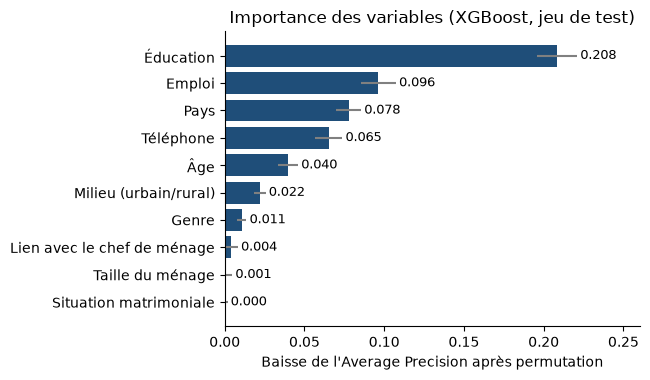

In [27]:
groupes = {
    "Éducation": ["education_level"],
    "Emploi": ["job_type"],
    "Téléphone": ["cellphone_access"],
    "Pays": ["country"],
    "Genre": ["gender_of_respondent"],
    "Âge": ["age_of_respondent", "age_group", "flag_age_outlier"],
    "Lien avec le chef de ménage": ["relationship_with_head", "flag_age_role"],
    "Milieu (urbain/rural)": ["location_type"],
    "Situation matrimoniale": ["marital_status"],
    "Taille du ménage": ["household_size", "flag_hh_outlier"],
}

rng = np.random.RandomState(42)
importance = {}
for nom, colonnes in groupes.items():
    baisses_ap, baisses_auc = [], []
    for _ in range(20):
        indices = rng.permutation(len(X_test))
        X_perm = X_test.copy()
        X_perm[colonnes] = X_test[colonnes].values[indices]
        proba_perm = modele_final.predict_proba(X_perm)[:, 1]
        baisses_ap.append(AP0 - average_precision_score(y_test, proba_perm))
        baisses_auc.append(AUC0 - roc_auc_score(y_test, proba_perm))
    importance[nom] = {
        "Baisse AP": np.mean(baisses_ap),
        "Écart-type AP": np.std(baisses_ap),
        "Baisse ROC-AUC": np.mean(baisses_auc),
    }

tableau_importance = pd.DataFrame(importance).T.sort_values("Baisse AP", ascending=False)
display(tableau_importance.round(4))

# Figure 10
ordre = tableau_importance["Baisse AP"].sort_values().index
with plt.style.context("default"):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    fig, ax = plt.subplots(figsize=(6.6, 3.9))
    ax.barh(ordre, tableau_importance.loc[ordre, "Baisse AP"],
            xerr=tableau_importance.loc[ordre, "Écart-type AP"], color=C1, ecolor="grey")
    for i, nom in enumerate(ordre):
        v = tableau_importance.loc[nom, "Baisse AP"]
        ax.text(v + tableau_importance.loc[nom, "Écart-type AP"] + .002, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlabel("Baisse de l'Average Precision après permutation")
    ax.set_title("Importance des variables (XGBoost, jeu de test)")
    ax.set_xlim(0, tableau_importance["Baisse AP"].max() * 1.25)
    plt.tight_layout(); plt.savefig("figures/f10_importance.png", dpi=110); plt.show()

### Vérification des hypothèses H1 à H6

- **H1** : lue dans le tableau d'importance ci-dessus (éducation et emploi en tête).
- **H2, H4, H6** : rapports de cotes (odds ratios) d'une régression logistique ajustée sur l'ensemble d'entraînement, avec une modalité de référence. Ils décrivent des associations, pas des causes.
- **H3** : on retire la variable pays et on compare les performances du modèle XGBoost.
- **H5** : on compare une régression logistique avec l'âge seul (linéaire) et avec les classes d'âge.

In [28]:
def pipeline_sur(colonnes, modele):
    """Pipeline de prétraitement + modèle restreint à un sous-ensemble de colonnes."""
    num = [c for c in numerical_features if c in colonnes]
    cat = [c for c in categorical_features if c in colonnes]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return ImbPipeline([("pretraitement", pre), ("modele", modele)])


def xgboost_pondere():
    return XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                         scale_pos_weight=rapport_classes, eval_metric="logloss",
                         random_state=42, n_jobs=1)


def rapport_de_cotes(colonnes, variable, modalite):
    """Odds ratio d'une modalité (référence = première modalité par ordre alphabétique)."""
    num = [c for c in numerical_features if c in colonnes]
    cat = [c for c in categorical_features if c in colonnes]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ])
    modele = ImbPipeline([("pretraitement", pre),
                          ("modele", LogisticRegression(max_iter=5000, C=1e6))])
    modele.fit(X_train[colonnes], y_train)
    noms = modele.named_steps["pretraitement"].get_feature_names_out()
    coefficients = modele.named_steps["modele"].coef_[0]
    position = list(noms).index(f"cat__{variable}_{modalite}")
    return float(np.exp(coefficients[position]))


toutes = list(X.columns)

# H3 : modèle sans la variable pays
sans_pays = [c for c in toutes if c != "country"]
modele_sans_pays = pipeline_sur(sans_pays, xgboost_pondere()).fit(X_train[sans_pays], y_train)
proba_sans_pays = modele_sans_pays.predict_proba(X_test[sans_pays])[:, 1]
print("H3 - modèle complet     : AP = %.4f | ROC-AUC = %.4f" % (AP0, AUC0))
print("H3 - modèle sans pays   : AP = %.4f | ROC-AUC = %.4f" % (
    average_precision_score(y_test, proba_sans_pays), roc_auc_score(y_test, proba_sans_pays)))

# H2 : téléphone
print("\nH2 - odds ratio téléphone (Yes vs No) : brut = %.2f | ajusté = %.2f" % (
    rapport_de_cotes(["cellphone_access"], "cellphone_access", "Yes"),
    rapport_de_cotes(toutes, "cellphone_access", "Yes")))
print("H2 - taux de bancarisation (%) selon le pays et l'accès au téléphone :")
display((df.groupby(["country", "cellphone_access"])["bank_account"].mean().unstack() * 100).round(1))

# H4 : genre
sans_educ_emploi = [c for c in toutes if c not in ("education_level", "job_type")]
print("\nH4 - odds ratio homme vs femme : brut = %.2f | sans éducation ni emploi = %.2f | complet = %.2f" % (
    rapport_de_cotes(["gender_of_respondent"], "gender_of_respondent", "Male"),
    rapport_de_cotes(sans_educ_emploi, "gender_of_respondent", "Male"),
    rapport_de_cotes(toutes, "gender_of_respondent", "Male")))

# H6 : milieu urbain, avec et sans le téléphone
sans_tel = [c for c in toutes if c != "cellphone_access"]
print("\nH6 - odds ratio urbain vs rural : brut = %.2f | sans téléphone = %.2f | avec téléphone = %.2f" % (
    rapport_de_cotes(["location_type"], "location_type", "Urban"),
    rapport_de_cotes(sans_tel, "location_type", "Urban"),
    rapport_de_cotes(toutes, "location_type", "Urban")))

# H5 : non-linéarité de l'âge (régression logistique pondérée)
print("\nH5 - régression logistique pondérée :")
variantes = {
    "âge linéaire": [c for c in toutes if c not in ("age_group", "flag_age_outlier")],
    "classes d'âge": [c for c in toutes if c not in ("age_of_respondent", "flag_age_outlier")],
}
for nom, colonnes in variantes.items():
    lr = pipeline_sur(colonnes, LogisticRegression(max_iter=3000, C=1e6, class_weight="balanced"))
    lr.fit(X_train[colonnes], y_train)
    p = lr.predict_proba(X_test[colonnes])[:, 1]
    print("   %-14s : AP = %.4f | ROC-AUC = %.4f" % (nom, average_precision_score(y_test, p), roc_auc_score(y_test, p)))

H3 - modèle complet     : AP = 0.5794 | ROC-AUC = 0.8660
H3 - modèle sans pays   : AP = 0.5573 | ROC-AUC = 0.8486

H2 - odds ratio téléphone (Yes vs No) : brut = 12.66 | ajusté = 5.69
H2 - taux de bancarisation (%) selon le pays et l'accès au téléphone :


cellphone_access,No,Yes
country,,
Kenya,4.8,30.5
Rwanda,1.3,13.6
Tanzania,0.5,15.0
Uganda,1.6,11.7



H4 - odds ratio homme vs femme : brut = 1.97 | sans éducation ni emploi = 1.62 | complet = 1.51



H6 - odds ratio urbain vs rural : brut = 1.66 | sans téléphone = 1.32 | avec téléphone = 1.34

H5 - régression logistique pondérée :
   âge linéaire   : AP = 0.5510 | ROC-AUC = 0.8549


   classes d'âge  : AP = 0.5540 | ROC-AUC = 0.8564
